# 02 · Clean and split

Load May and June only. Cleaning is stateless; fixed bounds never learn from a held-out distribution.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Markdown, Image
from taxi_tip.config import ROOT, REPORTS, ARTIFACTS
from taxi_tip.data import read_split, clean_trips
print("Project:", ROOT)


Project: C:\Users\mateo\OneDrive\Documents\ChatGPT\ML_project


In [2]:
from taxi_tip.data import payment_audit
may_raw = read_split("train")
june_raw = read_split("validation")
may, may_audit = clean_trips(may_raw)
june, june_audit = clean_trips(june_raw)
display(pd.DataFrame({"month": ["May", "June"], "raw_n": [len(may_raw), len(june_raw)], "eligible_n": [len(may), len(june)], "positive_rate": [may.generous_tip.mean(), june.generous_tip.mean()]}))
display(may_audit)
display(june_audit)

,month,raw_n,eligible_n,positive_rate
0,May,199999,129956,0.561667
1,June,200001,123162,0.595387


,step,decision,before,remaining,removed,card_positive_rate
0,Raw rows,audit; positive rate denominator is eligible c...,199999,199999,0,0.560977
1,Exact duplicates,drop duplicate rows,199999,199999,0,0.560977
2,Observable card tips,"drop cash, flex, no-charge, disputes, unknown ...",199999,133571,66428,0.560977
3,Positive fare,"drop zero, negative, missing or infinite fares",133571,133558,13,0.560977
4,Valid tip,"drop negative, missing or infinite tips",133558,133558,0,0.560977
5,Nonnegative charges,drop negative or infinite fees; missing fees i...,133558,133558,0,0.560977
6,Plausible duration,"drop missing, <30 seconds or >4 hours",133558,130303,3255,0.561568
7,Plausible distance,"drop missing, <0.01 or >100 miles",130303,129961,342,0.561645
8,Plausible average speed,drop >100 mph,129961,129956,5,0.561667
9,Retain flagged cases,"flag unknown zones, nonstandard rates and unkn...",129956,129956,0,0.561667


,step,decision,before,remaining,removed,card_positive_rate
0,Raw rows,audit; positive rate denominator is eligible c...,200001,200001,0,0.593469
1,Exact duplicates,drop duplicate rows,200001,200001,0,0.593469
2,Observable card tips,"drop cash, flex, no-charge, disputes, unknown ...",200001,126923,73078,0.593469
3,Positive fare,"drop zero, negative, missing or infinite fares",126923,126898,25,0.593469
4,Valid tip,"drop negative, missing or infinite tips",126898,126898,0,0.593469
5,Nonnegative charges,drop negative or infinite fees; missing fees i...,126898,126898,0,0.593469
6,Plausible duration,"drop missing, <30 seconds or >4 hours",126898,123541,3357,0.595551
7,Plausible distance,"drop missing, <0.01 or >100 miles",123541,123162,379,0.595387
8,Plausible average speed,drop >100 mph,123162,123162,0,0.595387
9,Retain flagged cases,"flag unknown zones, nonstandard rates and unkn...",123162,123162,0,0.595387


## Prove the observability problem

The table below reports recorded tips. Non-card rates do not measure actual generosity. Card-only eligibility prevents cash zeros from entering the negative class.

In [3]:
display(payment_audit(may_raw))

,payment_type,trips,valid_fare_trips,recorded_nonzero_tip_rate,recorded_25pct_rate,interpretation
0,0,46601,46539,0.093384,0.028449,not an observable card-tip target
1,1,133571,133558,0.901863,0.560977,observable target
2,2,18149,17934,0.000000,0.000000,not an observable card-tip target
3,3,570,473,0.000000,0.000000,not an observable card-tip target
4,4,1108,663,0.000000,0.000000,not an observable card-tip target


In [4]:
from taxi_tip.evaluation import rate_table, SLICE_COLUMNS
for column in SLICE_COLUMNS:
    display(Markdown(f"### {column}"))
    display(rate_table(may, column))

### fare_band

,fare_band,n,positives,rate,lower_95,upper_95,difference_pp,practically_large
0,0–10,38833,29568,0.761414,0.757149,0.765627,19.974724,True
1,10–20,50396,33072,0.656243,0.652084,0.660377,9.457553,True
2,20–40,26550,6664,0.250998,0.245819,0.256249,-31.066891,True
3,40–80,13083,3509,0.268211,0.260688,0.275869,-29.345637,True
4,80+,1094,179,0.163620,0.142883,0.186711,-39.804728,True


### distance_band

,distance_band,n,positives,rate,lower_95,upper_95,difference_pp,practically_large
0,0–2,73538,52167,0.709388,0.706096,0.712659,14.772132,True
1,10–20,9762,2111,0.216247,0.208192,0.224524,-34.542035,True
2,20+,1223,150,0.122649,0.105437,0.142225,-43.901780,True
3,2–5,33271,15109,0.454119,0.448775,0.459474,-10.754782,True
4,5–10,12162,3455,0.284082,0.276136,0.292164,-27.758546,True


### duration_band

,duration_band,n,positives,rate,lower_95,upper_95,difference_pp,practically_large
0,0–10,43274,32383,0.748325,0.744214,0.752391,18.665760,True
1,10–20,45591,29455,0.646070,0.641669,0.650447,8.440347,True
2,20–40,29023,9036,0.311339,0.306037,0.316691,-25.032774,True
3,40–60,7409,1562,0.210825,0.201688,0.220261,-35.084235,True
4,60+,4659,556,0.119339,0.110342,0.128963,-44.232811,True


... (10 outputs left out)

### unknown_zone

,unknown_zone,n,positives,rate,lower_95,upper_95,difference_pp,practically_large
0,0,129197,72730,0.562939,0.560232,0.565642,0.127174,False
1,1,759,262,0.345191,0.312224,0.379718,-21.647598,True


### nonstandard_rate

,nonstandard_rate,n,positives,rate,lower_95,upper_95,difference_pp,practically_large
0,0,117922,72135,0.611718,0.608933,0.614496,5.005089,True
1,1,12034,857,0.071215,0.066755,0.075948,-49.045213,True


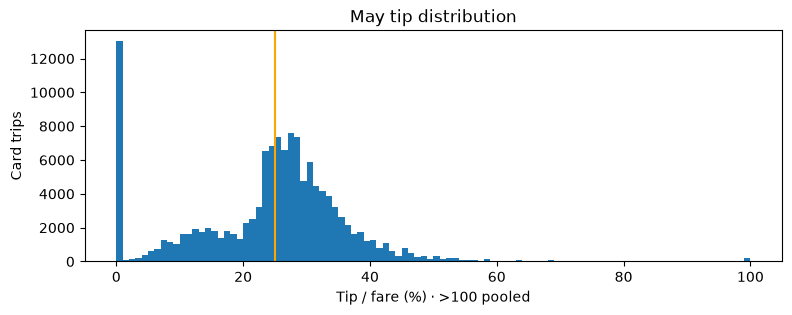

In [5]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(9, 3))
ax.hist(may.tip_pct.clip(upper=100), bins=100)
ax.axvline(25, color="orange")
ax.set(xlabel="Tip / fare (%) · >100 pooled", ylabel="Card trips", title="May tip distribution")
plt.show()

## Defend the policy

Unknown zones and nonstandard fares remain flagged. Missing passengers become unknown categories. Cash, flex fares, invalid monetary components and impossible journeys are excluded by explicit rules. Five-percentage-point rate differences are descriptive practical-effect flags; confidence intervals and sample sizes matter. July outcomes have not been examined here.